In [26]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

In [34]:
df = pd.read_csv(f"data/player_stats.csv")

In [41]:
data = df.drop(columns=['Team', 'Player', 'Active Player'])

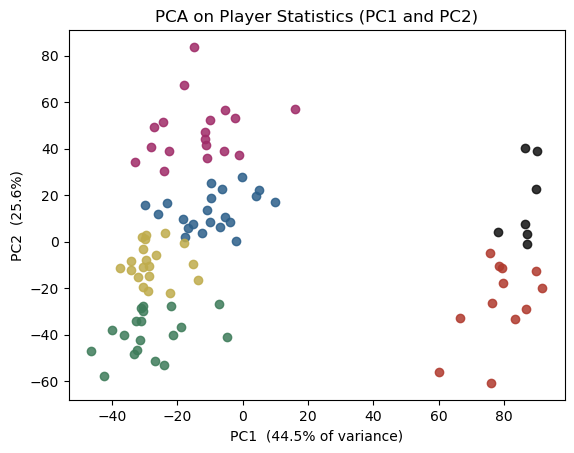

In [42]:
X_tilda = StandardScaler(with_std = False).fit_transform(data)
pca = PCA()
pca.fit(X_tilda)
pc1_scores = X_tilda @ pca.components_[0]
pc2_scores = X_tilda @ pca.components_[1]
pc_data = np.array([pc1_scores, pc2_scores]).T
km = KMeans(n_clusters = 6)
km.fit(pc_data)
pc_data = np.array([km.labels_, pc1_scores, pc2_scores]).T

labels = km.labels_
for i, colr in zip(np.unique(labels), ["#2C5F8A", "#B03A2E", "#3E7C5A", "#BFAC4C", "#111111", "#9F2B68"]):
    lab = labels == i
    plt.scatter(pc_data[lab, 1], pc_data[lab, 2], alpha=0.85, color=colr)
var_pc = pca.singular_values_**2 / (X_tilda.shape[0] - 1)
pct = 100 * var_pc / var_pc.sum()
plt.xlabel(f"PC1  ({pct[0]:.1f}% of variance)")
plt.ylabel(f"PC2  ({pct[1]:.1f}%)")
plt.title('PCA on Player Statistics (PC1 and PC2)')
plt.savefig('stats_pca12.png')
plt.show()

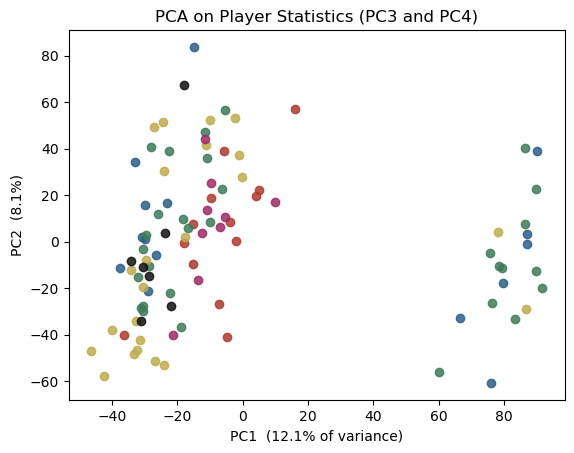

In [39]:
pc3_scores = X_tilda @ pca.components_[2]
pc4_scores = X_tilda @ pca.components_[3]
pc_data = np.array([pc3_scores, pc4_scores]).T
km = KMeans(n_clusters = 6)
km.fit(pc_data)
pc_data = np.array([km.labels_, pc1_scores, pc2_scores]).T

labels = km.labels_
for i, colr in zip(np.unique(labels), ["#2C5F8A", "#B03A2E", "#3E7C5A", "#BFAC4C", "#111111", "#9F2B68"]):
    lab = labels == i
    plt.scatter(pc_data[lab, 1], pc_data[lab, 2], alpha=0.85, color=colr)
var_pc = pca.singular_values_**2 / (X_tilda.shape[0] - 1)
pct = 100 * var_pc / var_pc.sum()
plt.xlabel(f"PC1  ({pct[2]:.1f}% of variance)")
plt.ylabel(f"PC2  ({pct[3]:.1f}%)")
plt.title('PCA on Player Statistics (PC3 and PC4)')
plt.savefig('stats_pca34.png')
plt.show()